# Q5 - XAI: Grad-CAM, Occlusion, and LIME on the Final ANN

Three explanation methods for the Final ANN (the best model by the primary metric):
**Grad-CAM** (architecture-specific, targets `layer4` - the block that was actually
fine-tuned, via `src/marco/xai.py`, also the primary method live in the web app),
**Occlusion** (model-agnostic, `src/marco/xai.py`), and **LIME** (model-agnostic,
superpixel-based). Three incorrect test predictions are analysed with all three methods,
plus two sanity checks.

**On test data here:** `scripts/final_eval.py` already computed and logged the official
test-set numbers (once, per hard rule 2). This notebook re-runs inference on those same
already-evaluated test images purely to identify *which* specific images were misclassified
for this required error analysis - no model, threshold, or hyperparameter decision is made
from anything here.

**What these explanations are not:** Grad-CAM, occlusion and LIME show what the model's
gradients/sensitivity point to for *this* prediction. None of them prove the model's true
internal reasoning, and none should be read as a guarantee - they are supporting evidence a
crystallographer can use to sanity-check a flagged drop, not a substitute for looking at it.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from PIL import Image
from lime import lime_image
from skimage.segmentation import mark_boundaries

from marco.data import CLASS_ORDER, build_transforms
from marco.model import build_model
from marco.xai import GradCAM, occlusion_map

PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data"
FIGURES_DIR = PROJECT_ROOT / "docs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

params = json.load(open(PROJECT_ROOT / "experiments" / "models" / "ann_final_history.json"))["params"]
model = build_model(params["backbone"], fine_tune_degree="layer4")
model.load_state_dict(torch.load(PROJECT_ROOT / "experiments" / "models" / "ann_final.pt", map_location="cpu"))
model.eval()
transform = build_transforms(train=False)

print(f"model: {params}")

model: {'backbone': 'resnet34', 'learning_rate': 0.001, 'batch_size': 32}


## Three incorrect test predictions

Picked from a full inference pass over the test split for diversity: a confident Crystals
false negative (the costly error for this project), a confident false-alarm on Crystals, and
a Crystals-vs-Other confusion - not cherry-picked for being flattering or easy to explain.

In [2]:
CASES = [
    {
        "path": "raw/Crystals/X0000045910743200502112353.png",
        "true": "Crystals", "note": "confident false negative (crystals_prob=0.008) - the costly error type",
    },
    {
        "path": "raw/Precipitate/C12_HighResolution_Precipitate_2.jpg",
        "true": "Precipitate", "note": "confident false alarm (crystals_prob=0.624)",
    },
    {
        "path": "raw/Crystals/RI01_03_000_0212_Proj1_Clon1_MC_0000MC011171_005_160811_05_04_02_00_99_002_001_RAI.jpg",
        "true": "Crystals", "note": "confused with Other, not Precipitate (crystals_prob=0.263)",
    },
]


def load_case(case):
    img = Image.open(DATA_DIR / case["path"]).convert("RGB")
    tensor = transform(img).unsqueeze(0)
    with torch.no_grad():
        probs = torch.softmax(model(tensor), dim=1)[0]
    pred_idx = int(probs.argmax())
    return img.resize((224, 224)), tensor, pred_idx, probs


for case in CASES:
    _, _, pred_idx, probs = load_case(case)
    print(f"{case['path'].split('/')[-1][:40]:42s} true={case['true']:11s} "
          f"pred={CLASS_ORDER[pred_idx]:11s} probs={[round(p, 3) for p in probs.tolist()]}")

X0000045910743200502112353.png             true=Crystals    pred=Precipitate probs=[0.0, 0.008, 0.0, 0.992]
C12_HighResolution_Precipitate_2.jpg       true=Precipitate pred=Crystals    probs=[0.041, 0.624, 0.106, 0.229]
RI01_03_000_0212_Proj1_Clon1_MC_0000MC01   true=Crystals    pred=Other       probs=[0.002, 0.262, 0.672, 0.063]


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

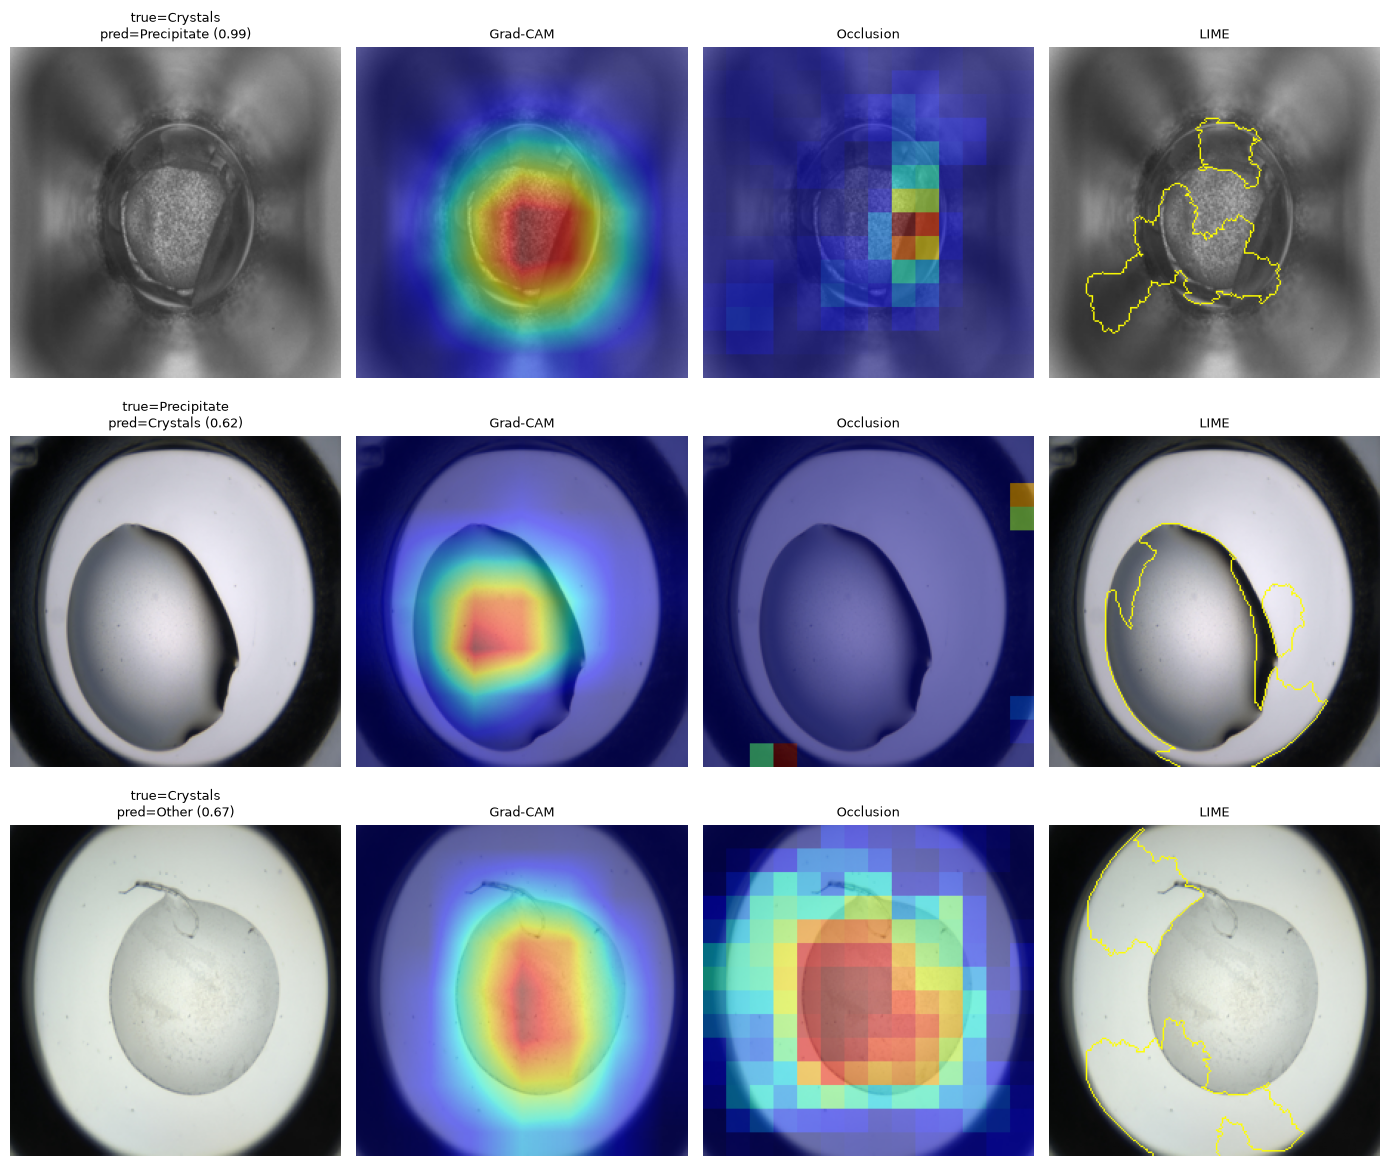

In [3]:
grad_cam = GradCAM(model)
explainer = lime_image.LimeImageExplainer()


def lime_predict_fn(images_np):
    batch = torch.stack([transform(Image.fromarray(im.astype("uint8"))) for im in images_np])
    with torch.no_grad():
        return torch.softmax(model(batch), dim=1).numpy()


def lime_overlay(img_resized: Image.Image, target_idx: int):
    img_np = np.array(img_resized)
    explanation = explainer.explain_instance(
        img_np, lime_predict_fn, labels=(target_idx,),
        hide_color=0, num_samples=150, random_seed=42,
    )
    temp, mask = explanation.get_image_and_mask(
        target_idx, positive_only=True, num_features=5, hide_rest=False
    )
    return mark_boundaries(temp / 255.0, mask)


fig, axes = plt.subplots(len(CASES), 4, figsize=(14, 4 * len(CASES)))
for row, case in enumerate(CASES):
    img_resized, tensor, pred_idx, probs = load_case(case)
    cam = grad_cam(tensor, pred_idx)
    occ = occlusion_map(model, tensor, pred_idx, patch_size=32, stride=16)
    lime_img = lime_overlay(img_resized, pred_idx)

    axes[row, 0].imshow(img_resized)
    axes[row, 0].set_title(f"true={case['true']}\npred={CLASS_ORDER[pred_idx]} ({probs[pred_idx]:.2f})", fontsize=9)
    axes[row, 1].imshow(img_resized); axes[row, 1].imshow(cam, cmap="jet", alpha=0.5)
    axes[row, 1].set_title("Grad-CAM", fontsize=9)
    axes[row, 2].imshow(img_resized); axes[row, 2].imshow(occ, cmap="jet", alpha=0.5)
    axes[row, 2].set_title("Occlusion", fontsize=9)
    axes[row, 3].imshow(lime_img)
    axes[row, 3].set_title("LIME", fontsize=9)
    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "q5_xai_comparison.png", dpi=130, bbox_inches="tight")
plt.show()

**Reading this:** on the false negative (row 1), all three methods point to the drop's central
region rather than the edges or background - the model is looking in a sensible place even
though it got the label wrong, suggesting the error is about feature *interpretation* (reading
the texture as precipitate-like) rather than attending to irrelevant background.

Row 2 is a genuine **disagreement**, not just a cosmetic difference: Grad-CAM and LIME both
point to the drop's centre, but occlusion's strongest effect is a small patch near the bottom
edge, with ~0 measured effect across most of the drop (checked directly - occlusion is exactly
0 at the centre pixel, and its peak is at a corner patch). This doesn't mean one method is
"wrong" - they measure different things. Grad-CAM/LIME reflect local gradient sensitivity;
occlusion reflects the effect of removing a whole 32x32 block, which can miss distributed
evidence spread across many small regions (no single block's removal moves the prediction
much) while still catching one unusually decisive block. The honest takeaway is that **no
single method here should be trusted alone** - cross-referencing multiple methods can surface
exactly this kind of disagreement, which is itself useful information, not noise to average
away.

Row 3 shows reasonable three-way agreement again, with LIME's superpixel boundaries coarser
than the smooth Grad-CAM/occlusion maps (an artefact of its segmentation step). Agreement
across independently-computed methods is reassuring where it happens, but it is still not
proof the highlighted region is the *true* reason for the prediction - a confounded feature
that correlates with the right region would produce the same agreement.

## Sanity check 1: occlude the Grad-CAM region, check the prediction changes

If Grad-CAM's highlighted region genuinely drives the prediction, covering exactly that region
should measurably change the predicted probability. Using the false-alarm case (row 2) since
it has a clear, concentrated Grad-CAM peak.

original Crystals probability: 0.624
after occluding the Grad-CAM region: 0.136
drop: 0.487


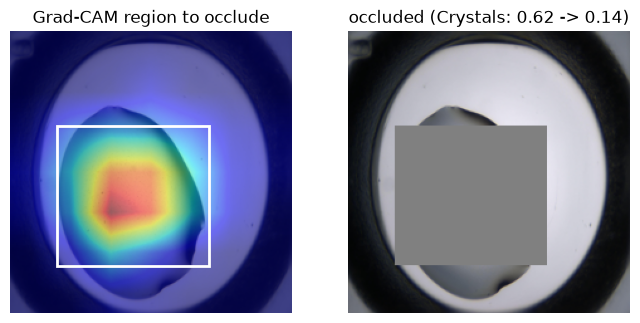

In [4]:
case = CASES[1]
img_resized, tensor, pred_idx, probs = load_case(case)
cam = grad_cam(tensor, pred_idx)

# bounding box of the top 20% most-activated Grad-CAM pixels
ys, xs = np.where(cam > np.quantile(cam, 0.8))
y0, y1, x0, x1 = ys.min(), ys.max(), xs.min(), xs.max()

occluded_tensor = tensor.clone()
occluded_tensor[:, :, y0:y1, x0:x1] = tensor.mean()
with torch.no_grad():
    occluded_probs = torch.softmax(model(occluded_tensor), dim=1)[0]

print(f"original {CLASS_ORDER[pred_idx]} probability: {probs[pred_idx]:.3f}")
print(f"after occluding the Grad-CAM region: {occluded_probs[pred_idx]:.3f}")
print(f"drop: {probs[pred_idx] - occluded_probs[pred_idx]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(img_resized); axes[0].imshow(cam, cmap="jet", alpha=0.5)
axes[0].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="white", lw=2))
axes[0].set_title("Grad-CAM region to occlude"); axes[0].axis("off")
occluded_display = np.array(img_resized).copy()
occluded_display[y0:y1, x0:x1] = 128
axes[1].imshow(occluded_display)
axes[1].set_title(f"occluded ({CLASS_ORDER[pred_idx]}: {probs[pred_idx]:.2f} -> {occluded_probs[pred_idx]:.2f})")
axes[1].axis("off")
fig.savefig(FIGURES_DIR / "q5_sanity_occlusion.png", dpi=130, bbox_inches="tight")
plt.show()

## Sanity check 2: model randomisation (Adebayo et al., 2018)

A saliency method that looks identical on a trained model and an otherwise-identical model
with randomised weights isn't actually explaining what the model *learned* - see
`docs/references.md`. Here `layer4` and the head (the parts that were actually fine-tuned) are
re-initialised with fresh random weights, keeping the earlier ImageNet-pretrained layers
identical between the two models, and Grad-CAM is compared on the same image.

correlation between trained-model and randomised-model Grad-CAM: -0.303


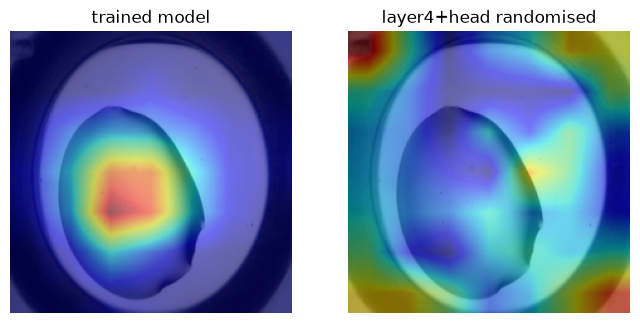

In [5]:
def randomize_trained_layers(m: nn.Module) -> None:
    for sub in [m.layer4, m.fc]:
        for module in sub.modules():
            if hasattr(module, "reset_parameters"):
                module.reset_parameters()


random_model = build_model(params["backbone"], fine_tune_degree="layer4")
randomize_trained_layers(random_model)
random_model.eval()
random_cam_fn = GradCAM(random_model)

case = CASES[1]
img_resized, tensor, pred_idx, probs = load_case(case)
trained_cam = grad_cam(tensor, pred_idx)
random_cam = random_cam_fn(tensor, pred_idx)

correlation = np.corrcoef(trained_cam.ravel(), random_cam.ravel())[0, 1]
print(f"correlation between trained-model and randomised-model Grad-CAM: {correlation:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(img_resized); axes[0].imshow(trained_cam, cmap="jet", alpha=0.5)
axes[0].set_title("trained model"); axes[0].axis("off")
axes[1].imshow(img_resized); axes[1].imshow(random_cam, cmap="jet", alpha=0.5)
axes[1].set_title("layer4+head randomised"); axes[1].axis("off")
fig.savefig(FIGURES_DIR / "q5_sanity_randomization.png", dpi=130, bbox_inches="tight")
plt.show()

## Summary for a crystallographer

Grad-CAM (shown live in the web app) highlights the region of a drop image that most
influenced the model's prediction. Use it as a pointer to *where to look*, not as a verdict -
cross-check the highlighted region against the actual image, the same way you would weigh any
single piece of evidence. The two sanity checks above give some confidence the highlighted
regions are meaningfully tied to what the model learned (occluding them changes the
prediction; randomising the trained layers changes the heatmap) - but no XAI method here
proves the model's true internal reasoning, and none should be treated as a guarantee,
especially on an incorrect prediction like the three analysed above.